Jeremy Barton<br>
Term Project: Milestone 1<br>
DSC550-T302<br>
Spring 2026

## WigglNet: Data Mining and Brokerage Service for E-Commerce Niche Market Sellers and Small to Mid-size Product Manufacturers

### Business Question

Small e-commerce sellers and product manufacturers struggle to understand what is popular, why and what will be popular in the future. This data could be retrieved by a search engine or AI, but there is value in using advanced models specially trained to identify people, organizations or entities related to a specific product category to discover these insights rather than a Large Language Model trained on everything, that happens to have picked up data related to a particular target market.

The question being asked in this business need is <i>"Can actionable insights for certain product categories be derived from various related web articles, BLS data and product pricing data?</i>"

A great way to examine this is to target `sentiment` which is the variable tied to the mood of a keyword or entity. It is broken down into three classes: positive, neutral and negative.

This is one of the most useful variables to analyze becuase it tells a client how to make decisions about these entities.

#### Creating the SQL Database connection

MariaDB is the database system used for development purposes.

In [24]:
# Imports and Processing
import sys
sys.path.insert(0, '/home/jeremy/Documents/GitHub/wigglnet')

import mariadb
import pandas as pd
from app.shared_utils.db_utils import get_db_config

# Get database configuration from .env file
config = get_db_config()

# Connect to DB
try:
    conn = mariadb.connect(
        host=config['host'],
        user=config['user'],
        password=config['password'],
        database=config['database'],
        port=config['port']
    )
    print("Successfully connected to MariaDB database")
except mariadb.Error as e:
    print(f"Error connecting to MariaDB Platform: {e}")
    sys.exit(1)

# Get the cursor
cur = conn.cursor()

Successfully connected to MariaDB database


#### Return Summary from Database

The SQL query is pulling back combined article, keyword, identity and sentiment information by joining to four other tables on either ARTICLE_ID or KEYWORD_ID. Using multiple tables with a JOIN, an overview of the joined insight data is stored in a dataframe. Because this is time series data, the query can ignore all rows where PUBLISHED_DATE is NULL.

In [25]:
# SQL Query to retrieve article data with keywords, entities, and sentiment
query = """
    SELECT
        a.ARTICLE_ID,
        a.TITLE,
        a.PUBLISHED_DATE,
        k.KEYWORD_TEXT,
        e.ENTITY_TEXT,
        e.ENTITY_TYPE,
        aes.SENTIMENT,
        aes.MENTIONS
    FROM WEBDATA.ARTICLES a
    LEFT JOIN WEBDATA.ARTICLE_KEYWORDS ak ON a.ARTICLE_ID = ak.ARTICLE_ID
    LEFT JOIN WEBDATA.KEYWORDS k ON ak.KEYWORD_ID = k.KEYWORD_ID
    LEFT JOIN WEBDATA.ARTICLE_ENTITY_SENTIMENT aes ON a.ARTICLE_ID = aes.ARTICLE_ID
    LEFT JOIN WEBDATA.ENTITIES e ON aes.ENTITY_ID = e.ENTITY_ID
    WHERE PUBLISHED_DATE IS NOT NULL
    AND published_date BETWEEN CURRENT_DATE - INTERVAL 1 YEAR AND CURRENT_DATE;
"""

# Execute query and load results into a DataFrame
df = pd.read_sql(query, conn)

/tmp/ipykernel_15466/1169704266.py:22: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


#### Exploring the Data

In [26]:
# Display basic info about the dataset
print(f"Dataset shape: {df.shape}")
print(f"\nColumn names: {df.columns.tolist()}")
print(f"\nFirst few rows:")
df.head()

Dataset shape: (14072, 8)

Column names: ['ARTICLE_ID', 'TITLE', 'PUBLISHED_DATE', 'KEYWORD_TEXT', 'ENTITY_TEXT', 'ENTITY_TYPE', 'SENTIMENT', 'MENTIONS']

First few rows:


,ARTICLE_ID,TITLE,PUBLISHED_DATE,KEYWORD_TEXT,ENTITY_TEXT,ENTITY_TYPE,SENTIMENT,MENTIONS
0,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Next,ORG,neutral,3
1,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,House,ORG,positive,3
2,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Eisenhart,PERSON,neutral,2
3,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Alexandra Gater,PERSON,positive,2
4,2,45 Clever Studio Apartment Ideas That Designer...,2025-11-05,ideas,Ikea,NORP,neutral,2


How many articles are in this dataset?

In [27]:
total_articles = df["ARTICLE_ID"].nunique()
print(f"There are {total_articles} articles in this dataset.")

There are 96 articles in this dataset.


<b>If there are only 132 articles, why are there 19,637 rows?<b>

This dataset includes information on metadata about keywords and enitities in an article, not just a list of each article.

Every keyword has an entity text, type, sentiment and number of mentions.

What are the max and min published dates?

In [28]:
max_pub = df["PUBLISHED_DATE"].max()
print(f"Max published date is {max_pub}")

min_pub = df["PUBLISHED_DATE"].min()
print(f"Min published date is {min_pub}")

Max published date is 2026-04-10 00:00:00
Min published date is 2025-04-21 00:00:00


#### Plotting Keyword Frequency Over Time


The first visualization is the frequency of the top 5 most used words over the past year. This graph is generated using matplotlib and seaborn. It can be used to compare which words were used more than others, or indicate a reaction in the use of a word with the change in frquency of another.

In [18]:
# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)

In [19]:
# Find the top 10 most frequent keywords
top_keywords = df['KEYWORD_TEXT'].value_counts().head(5)
print("Top 5 Keywords by Frequency:")
print(top_keywords)
print(f"\nTop keywords: {top_keywords.index.tolist()}")

Top 5 Keywords by Frequency:
KEYWORD_TEXT
home        793
room        723
space       685
designer    561
design      547
Name: count, dtype: int64

Top keywords: ['home', 'room', 'space', 'designer', 'design']


Above are the top keywords and a frequency count.

In [20]:
# Filter data to only include top keywords
top_keyword_list = top_keywords.index.tolist()
df_top_keywords = df[df['KEYWORD_TEXT'].isin(top_keyword_list)].copy()

For the PUBLISHED_DATE data to be read properly by matplotlib it should be in `datetime` format, which can be converted to using pandas `to_datetime`.

In [21]:
# Convert PUBLISHED_DATE to datetime
df_top_keywords['PUBLISHED_DATE'] = pd.to_datetime(df_top_keywords['PUBLISHED_DATE'])

Group by date and keyword to count word frequency over time. Before this though, duplicates should be dropped.

In [22]:
keyword_freq = df_top_keywords.drop_duplicates(subset=['ARTICLE_ID', 'KEYWORD_TEXT'])
freq_time = keyword_freq.groupby([pd.Grouper(key='PUBLISHED_DATE', freq='ME'), 'KEYWORD_TEXT']).size().reset_index(name='frequency')

# Pivot the data for easier plotting
keyword_pivot = freq_time.pivot(index='PUBLISHED_DATE', columns='KEYWORD_TEXT', values='frequency').fillna(0)

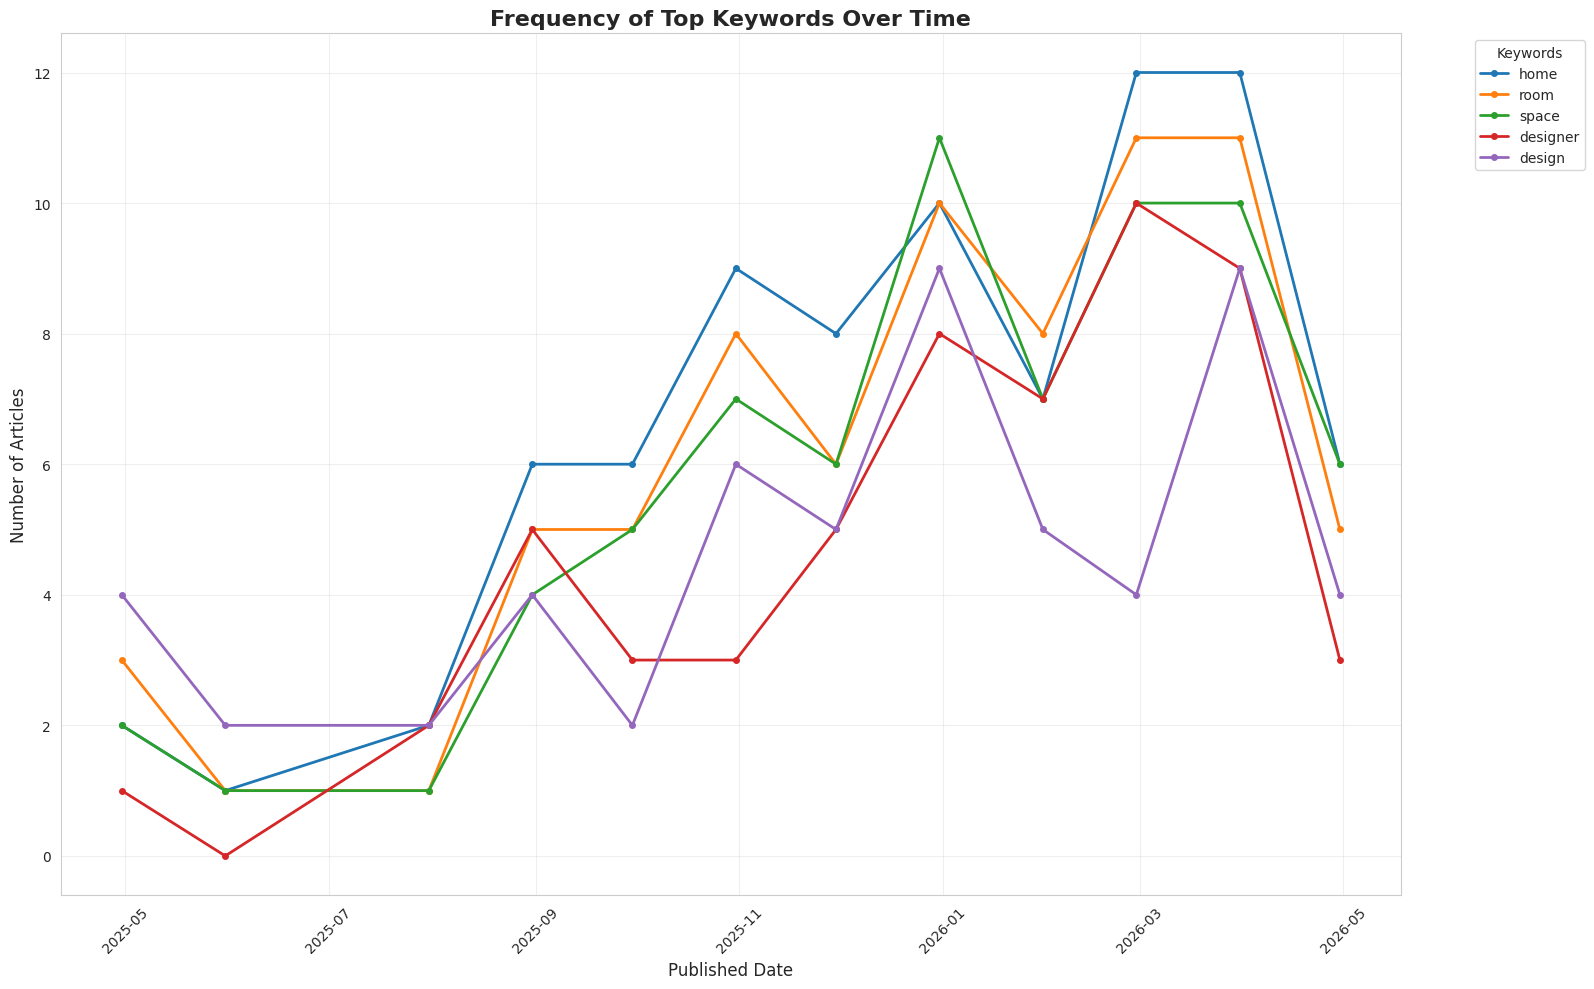


Date range: 2025-04-30 00:00:00 to 2026-04-30 00:00:00
Total months covered: 12


In [23]:
# Create the plot
plt.figure(figsize=(16, 10))
for keyword in top_keyword_list:
    if keyword in keyword_pivot.columns:
        plt.plot(keyword_pivot.index, keyword_pivot[keyword], marker='o', label=keyword, linewidth=2, markersize=4)

plt.title('Frequency of Top Keywords Over Time', fontsize=16, fontweight='bold')
plt.xlabel('Published Date', fontsize=12)
plt.ylabel('Number of Articles', fontsize=12)
plt.legend(title='Keywords', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"\nDate range: {keyword_pivot.index.min()} to {keyword_pivot.index.max()}")
print(f"Total months covered: {len(keyword_pivot)}")